##### EDA and Visualization

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv(r"../data/cleaned/diwali_sales_cleaned.csv")
df["Age_Group"] = df["Age_Group"].astype("category") 
df.shape

(11239, 13)

In [3]:
total_revenue = df["Amount"].sum()
print(f"Total revenue in this dataset: {total_revenue}$")

Total revenue in this dataset: 106249132$


In [4]:
category =(
    df.groupby("Product_Category") ["Amount"]
    .agg(revenue ="sum", rows = "count")
    .sort_values("revenue", ascending= False)

)

category["share_pct"] = (category["revenue"] / category["revenue"].sum() * 100).round(2)
category

,revenue,rows,share_pct
Product_Category,,,
Food,33933883,2490,31.94
Clothing & Apparel,16495019,2655,15.52
Electronics & Gadgets,15643846,2087,14.72
Footwear & Shoes,15575209,1059,14.66
Furniture,5440052,352,5.12
Games & Toys,4331694,386,4.08
Sports Products,3635933,356,3.42
Beauty,1959484,422,1.84
Auto,1958610,97,1.84


##### Visualization

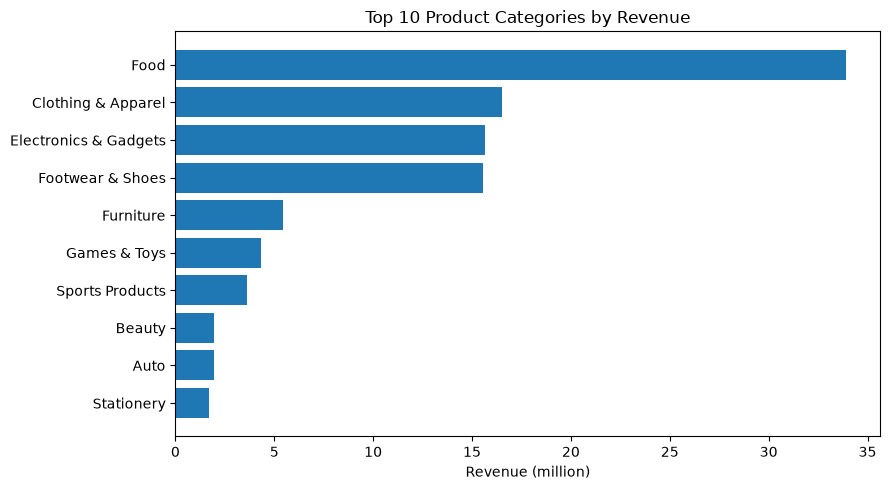

In [5]:
top10 = category.head(10).sort_values("revenue")   

plt.figure(figsize=(9, 5))
plt.barh(top10.index, top10["revenue"] / 1e6)
plt.xlabel("Revenue (million)")
plt.title("Top 10 Product Categories by Revenue")
plt.tight_layout()
plt.savefig("../images/q1_revenue_by_category.png", dpi=150)
plt.show()

<b>Food</b> products account for<b> 32%</b> of total revenue, which is more than double the revenue of the next category. The top four categories <b>(food products, apparel, electronics, and footwear)</b> generate approximately <b>77%</b> of total revenue; therefore, priority should be given to these categories regarding inventory and marketing budgets.

##### Revenue by State

In [6]:
state = (
    df.groupby("State") ["Amount"]
    .agg(revenue = "sum", rows = "count")
    .sort_values("revenue", ascending= False)
)

state["share_pct"] = (state["revenue"] / state["revenue"].sum() * 100). round(2)
state

,revenue,rows,share_pct
State,,,
Uttar Pradesh,19374968,1944,18.24
Maharashtra,14427543,1525,13.58
Karnataka,13523540,1304,12.73
Delhi,11603819,1104,10.92
Madhya Pradesh,8101142,921,7.62
Andhra Pradesh,8037147,811,7.56
Himachal Pradesh,4963368,608,4.67
Haryana,4220175,452,3.97
Bihar,4022757,434,3.79


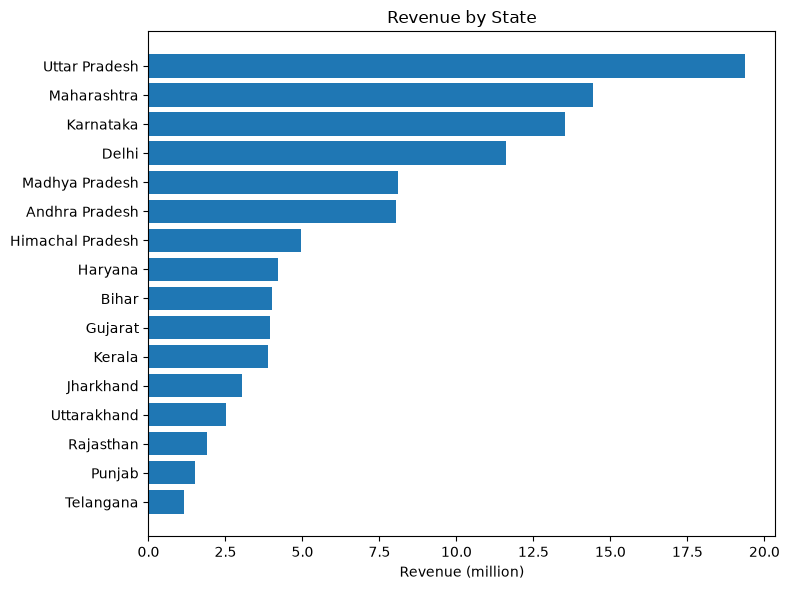

In [7]:
s = state["revenue"].sort_values() / 1e6  

plt.figure(figsize=(8, 6))
plt.barh(s.index, s.values)
plt.xlabel("Revenue (million)")
plt.title("Revenue by State")
plt.tight_layout()
plt.savefig("../images/q2_revenue_by_state.png", dpi=150)
plt.show()

In [8]:
top, bottom = state["revenue"].idxmax(), state["revenue"].idxmin()
print(top, "vs", bottom, "->", round(state["revenue"].max() / state["revenue"].min(), 1), "times")

Uttar Pradesh vs Telangana -> 16.8 times


##### Revenue by Zone

In [9]:
zone = (
    df.groupby("Zone")["Amount"]
    .agg(revenue="sum", rows="count")
    .sort_values("revenue", ascending=False)
)
zone["share_pct"] = (zone["revenue"] / zone["revenue"].sum() * 100).round(1)
zone

,revenue,rows,share_pct
Zone,,,
Central,41600873,4289,39.2
Southern,26606669,2693,25.0
Western,18373625,1952,17.3
Northern,12618752,1491,11.9
Eastern,7049213,814,6.6


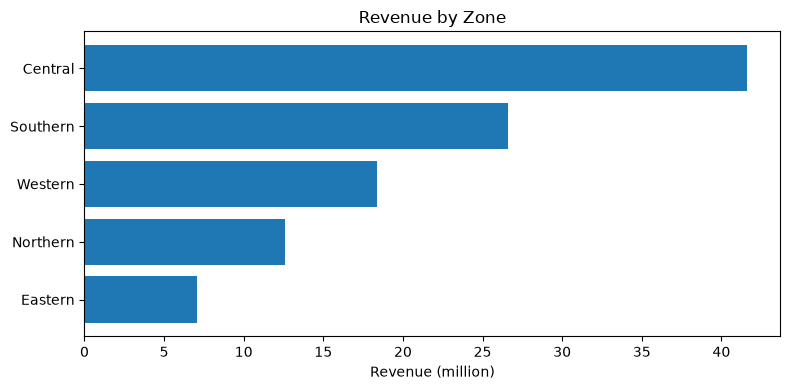

In [10]:
z = zone["revenue"].sort_values() / 1e6

plt.figure(figsize=(8, 4))
plt.barh(z.index, z.values)
plt.xlabel("Revenue (million)")
plt.title("Revenue by Zone")
plt.tight_layout()
plt.savefig("../images/q2_revenue_by_zone.png", dpi=150)
plt.show()

In [11]:
top, bottom = zone["revenue"].idxmax(), zone["revenue"].idxmin()
print(top, "vs", bottom, "->", round(zone["revenue"].max() / zone["revenue"].min(), 1), "times")

Central vs Eastern -> 5.9 times


The top three states (<b>Uttar Pradesh, Maharashtra, and Karnataka</b>) account for approximately <b>44.5%</b>of the total revenue, while the <b>Central</b> region alone contributes <b>39.2%</b>. In contrast, the <b>Eastern</b> region’s contribution is only <b>6.6%</b>; furthermore, the state with the highest revenue (Uttar Pradesh) generates about <b>16.8 times</b> more revenue than the state with the lowest revenue (<b>Telangana</b>).Therefore, priority should be given to inventory and marketing budgets for the top-performing states and central regions. On the other hand, the eastern region requires a separate review—a decision must be made as to whether to expand business operations there or to keep expenditures limited.

##### Revenue by gender

In [12]:
gender = df.groupby("Gender", observed= True) ["Amount"]. agg(revenue = "sum", rows = "count")
gender["share_pct"] = (gender["revenue"] / gender["revenue"].sum() * 100).round(1)
gender["ave_per_row"] = (gender["revenue"] / gender["rows"]).round(0)
gender

,revenue,rows,share_pct,ave_per_row
Gender,,,,
F,74335856,7832,70.0,9491.0
M,31913276,3407,30.0,9367.0


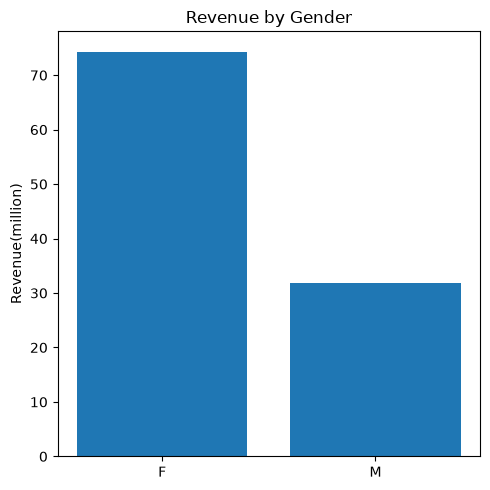

In [13]:
plt.figure(figsize=(5, 5))
plt.bar(gender.index, gender["revenue"] / 1e6)
plt.ylabel("Revenue(million)")
plt.title("Revenue by Gender")
plt.tight_layout()
plt.savefig("../images/q3_revenue_by_gender.png", dpi=150)
plt.show()

**Gender:** **70%** of total revenue **(74.3 million)** is generated by women, while **30%** **(31.9 million)** comes from men. The average spend per transaction is nearly identical (approximately **9,500** for women and **9,400** for men); however, because women shop more frequently **(7,832 transactions by women compared to 3,407 by men)**, their contribution to total revenue is significantly higher. Therefore, marketing efforts should prioritize women, and offers should be designed to encourage them to shop repeatedly.

##### Revenue Age Group

In [14]:
age = df.groupby("Age_Group", observed= True) ["Amount"].agg(revenue ="sum", rows = "count")
age["share_pct"] = (age["revenue"] / age["revenue"]. sum() * 100).round(1)
age["ave_per_row"] = (age["revenue"] / age["rows"]).round(0)
age

,revenue,rows,share_pct,ave_per_row
Age_Group,,,,
0-17,2699653,296,2.5,9120.0
18-25,17240732,1879,16.2,9175.0
26-35,42613443,4541,40.1,9384.0
36-45,22144996,2283,20.8,9700.0
46-50,9207844,983,8.7,9367.0
51-55,8261477,830,7.8,9954.0
55+,4080987,427,3.8,9557.0


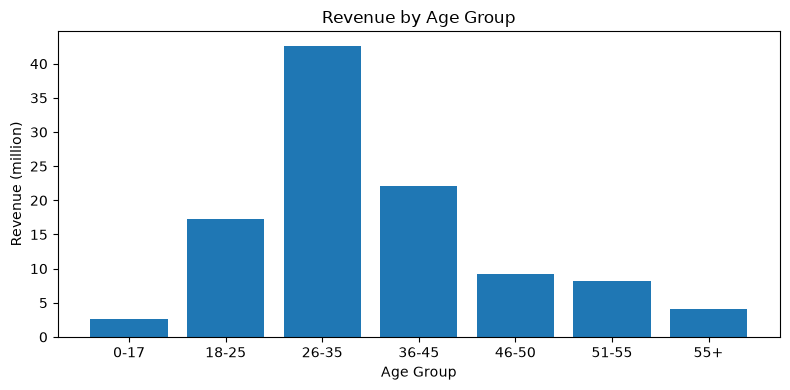

In [15]:
plt.figure(figsize=(8, 4))
plt.bar(age.index.astype(str), age["revenue"] / 1e6)
plt.xlabel("Age Group")
plt.ylabel("Revenue (million)")
plt.title("Revenue by Age Group")
plt.tight_layout()
plt.savefig("../images/q3_revenue_by_age_group.png", dpi=150)
plt.show()

**Age Group:** Customers aged **26–35 account for 40.1% of total revenue**, while three age groups spanning **18 to 45** years collectively contribute approximately **77%** of the total revenue. Children (aged 0–17) and customers over the age of 55 contribute only 2.5% and 3.8%, respectively. The average expenditure per purchase is relatively consistent across all age groups (ranging approximately between 9,100 and 10,000).However, spending is somewhat higher among the 51–55 (9,954) and 36–45 (9,700) age groups. Therefore, marketing efforts should primarily target customers aged 18–45. On the other hand, for customers over the age of 55, it may be worth experimenting with premium offers, as they tend to spend relatively more per purchase.

##### Revenue by Marital Status

In [16]:
marital = df.groupby("Marital_Status", observed= True) ["Amount"].agg(revenue = "sum", rows ="count")
marital["share_pct"] = (marital["revenue"] / marital["revenue"].sum() * 100).round(1)
marital["ave_per_row"] = (marital["revenue"] / marital["rows"]).round(0)
marital

,revenue,rows,share_pct,ave_per_row
Marital_Status,,,,
0,62125386,6518,58.5,9531.0
1,44123746,4721,41.5,9346.0


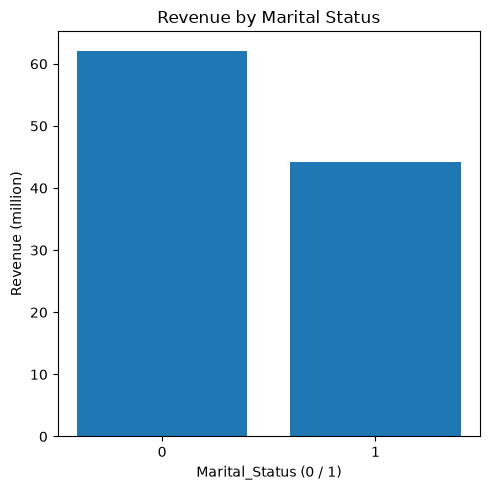

In [17]:
plt.figure(figsize=(5, 5))
plt.bar(marital.index.astype(str), marital["revenue"] / 1e6)
plt.xlabel("Marital_Status (0 / 1)")
plt.ylabel("Revenue (million)")
plt.title("Revenue by Marital Status")
plt.tight_layout()
plt.savefig("../images/q3_revenue_by_marital_status.png", dpi=150)
plt.show()

**Marital Status:** Customers with a marital status of **0** account for **58.5%** of total revenue, while those with a marital status of **1** account for **41.5%**. The average expenditure per transaction is nearly the same for both groups (approximately **9,500** and **9,300**, respectively); this indicates that the difference in revenue stems from a variation in the number of transactions (6,518 versus 4,721), rather than higher spending per transaction.Therefore, using marital status alone as a basis for customer targeting is not very effective. Instead, it becomes far more meaningful when combined with other factors, such as age and gender.